# Pricing Model for Sublimation Print Orders
**Author:** Yana Atanasova

**Course:** Final Exam Project

**Type of project:** Application of mathematics (linear algebra and least squares) in pricing

## 1. Title & Introduction
When I price a custom sublimation print order (mugs, t-shirts, mousepads,
invitations), I need to know how much it actually costs me: blanks, ink,
paper, press time, design time and wasted items. Pricing by gut feeling often
leads to losing money on small orders or being too expensive on large ones.

In this project I build a **linear regression model** that predicts the
cost of an order from its characteristics, and then use it to recommend a
selling price with a profit margin.

You will see how a statistical model is built step by step: cleaning
the data, exploring it, deriving the mathematics of least squares, fitting
the model with matrices and with libraries, checking its quality, and
turning the result into a practical price calculator.

The mathematical core of the project is linear algebra: the cost model is written in matrix form $y = X\beta + \varepsilon$, the coefficients are obtained by the method of least squares from the normal equations $X^T X \beta = X^T y$, and Ridge regression is studied as a way to stabilize the solution when $X^T X$ is almost singular. The statistical modelling and the Python code are the tools that apply this mathematics to a real pricing problem.

*Note: the dataset used here is simulated, because I did not have enough
structured records of real orders. The method can be applied to real data
without changes.*

In [ ]:
# %pip install pandas numpy matplotlib statsmodels scikit-learn

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## 2. Problem Formulation

### Real-world problem

When pricing a custom sublimation print order, it is necessary to estimate the
true production cost before setting the selling price.

The production cost may depend on the product type, quantity, printed area,
ink consumption, paper consumption, heat-press time, design time and production
waste.

The goal of this project is to build a statistical model that estimates the
production cost of a new order and then uses this estimate to calculate a
recommended selling price.

### Mathematical formulation

Let $y$ denote the total production cost of an order, measured in EUR.

The explanatory variables are:

- $x_1$ = quantity
- $x_2$ = ink used in millilitres
- $x_3$ = number of paper sheets
- $x_4$ = heat-press time in minutes
- $x_5$ = design time in minutes
- $x_6$ = percentage of wasted production
- $d_k$ = indicator of the product type: $d_k = 1$ if the order is of product $k$ (mug, mousepad, phone case or t-shirt) and $d_k = 0$ otherwise. Invitations are the reference product, so all four indicators are zero for them.

The printed area is available in the data, but it is not used in the model: its correlation with the cost is weak (0.12), and its effect is already reflected in the ink and paper consumption.

We start with a multiple linear regression model:

$$
y = \beta_0 + \sum_{j=1}^{6}\beta_j x_j + \sum_{k=1}^{4}\gamma_k d_k + \varepsilon .
$$

The cost of one more item differs between products (see Section 5), so the final model also contains an interaction between the quantity and the product type:

$$
y = \beta_0 + \sum_{j=1}^{6}\beta_j x_j + \sum_{k=1}^{4}\gamma_k d_k + \sum_{k=1}^{4}\delta_k\,(x_1 d_k) + \varepsilon 
$$

where:

- $\beta_0$ is the intercept;
- $\beta_j$ is the expected change in the cost when $x_j$ increases by one unit, while the other variables remain constant;
- $\gamma_k$ is the difference in the base cost of product $k$ compared with the invitation;
- $\delta_k$ is the additional cost of one more item of product $k$ compared with the invitation;
- $\varepsilon$ is the random error that is not explained by the model.

For a new order, the estimated production cost is:

$$
\hat{y} = \hat\beta_0 + \sum_{j=1}^{6}\hat\beta_j x_j + \sum_{k=1}^{4}\hat\gamma_k d_k + \sum_{k=1}^{4}\hat\delta_k\,(x_1 d_k).
$$

### Selling price

The estimated production cost alone is not the final selling price.

Let $m$ denote the desired profit margin, where:

$$
0 \le m < 1
$$

If $P$ is the selling price, the profit is:

$$
\text{Profit} = P-\hat{y}
$$

The profit margin is defined as:

$$
m = \frac{P-\hat{y}}{P}
$$

Solving the equation for $P$:

$$
P-\hat{y}=mP
$$

$$
P(1-m)=\hat{y}
$$

Therefore, the recommended selling price is:

$$
\boxed{
P=\frac{\hat{y}}{1-m}
}
$$

For example, if the predicted production cost is $20$ EUR and the desired
profit margin is $30\%$, then:

$$
P=\frac{20}{1-0.30}
=\frac{20}{0.70}
\approx 28.57\text{ EUR}
$$

The resulting profit is:

$$
28.57-20=8.57\text{ EUR}
$$

and the profit margin is:

$$
\frac{8.57}{28.57}\approx0.30=30\%
$$

### Assumptions

The regression model is based on the following assumptions:

1. The relationship between the production cost and the explanatory variables
   is approximately linear.
2. The observations are independent.
3. The expected value of the error is zero:

$$
E(\varepsilon)=0
$$

4. The variance of the errors is approximately constant:

$$
Var(\varepsilon)=\sigma^2
$$

5. The residuals are approximately normally distributed when statistical
   inference is required.
6. The observed orders are representative of the type of orders for which the
   model will be used.

### Limitations

The dataset is simulated rather than collected from a large number of real
business orders. Therefore, the results describe the simulated environment
and should not be interpreted as a universal pricing formula.

The model may also fail to capture factors such as quantity discounts,
supplier price changes, electricity costs, packaging costs, marketplace fees
and seasonal demand.

## 3. Mathematical Background
**Matrix form.** Suppose we have $N$ orders. We collect the predictors in a
matrix $X$ of size $N \times (p+1)$, where each row is one order and the
first column is all ones (it corresponds to $\beta_0$). The costs form a
vector $y$ and the coefficients a vector $\beta$. The model becomes

$$y = X\beta + \varepsilon.$$

**Ordinary Least Squares (OLS).** We choose $\beta$ so that the predictions
$X\beta$ are as close as possible to $y$, by minimizing the sum of squared
errors:

$$S(\beta) = \|y - X\beta\|^2 = (y - X\beta)^T (y - X\beta).$$

To find the minimum, we take the derivative with respect to $\beta$ and set
it to zero:

$$\frac{\partial S}{\partial \beta} = -2X^T y + 2X^T X \beta = 0
\quad\Longrightarrow\quad X^T X \beta = X^T y.$$

If the columns of $X$ are linearly independent, $X^T X$ is invertible and

$$\hat\beta = (X^T X)^{-1} X^T y.$$

**Residuals.** The fitted values are $\hat y = X\hat\beta$ and the residuals
are $e_i = y_i - \hat y_i$. A good model has small residuals without any
visible pattern.

**Coefficient of determination.** $R^2$ measures what fraction of the
variation in the costs the model explains:

$$R^2 = 1 - \frac{\sum_i (y_i - \hat y_i)^2}{\sum_i (y_i - \bar y)^2}.$$

For OLS with an intercept, $R^2$ on the training data is between $0$ and $1$; values close to $1$ mean a good fit. On new data (test set or cross-validation) it can be negative, which means the model predicts worse than the simple mean.

**Model assumptions.** OLS gives reliable results when the assumptions from
Section 2 hold: linearity, independent errors with mean zero and constant
variance, and approximately normal errors. We check them in Section 7 using
residual plots.

**Ridge regression.** When predictors are strongly correlated (for example,
ink used and quantity), the coefficients of OLS can become unstable. Ridge
regression adds a penalty for large coefficients:

$$\hat\beta_{ridge} = \arg\min_\beta \; \|y - X\beta\|^2 + \lambda \sum_{j=1}^{p} \beta_j^2
\quad\Longrightarrow\quad \hat\beta_{ridge} = (X^T X + \lambda I)^{-1} X^T y,$$

where $\lambda \ge 0$ (called alpha in scikit-learn) controls the strength of the penalty.
For $\lambda = 0$ we get OLS back. For simplicity the closed form above assumes that the data are centered, so the intercept is not penalized. We compare both methods in Section 8.

## 4. Data

**Source.** The dataset is **simulated**. I did not have enough structured
records of real orders, so I generated 60 orders with the script
`generate_data.py`. Each order's cost is computed from a known formula
(prices of blanks, ink, paper and labor) plus a small random noise. This
means the model can be tested in a controlled setting, but the results
describe the simulation and not a real workshop.

**Columns.**

| Column | Description |
|---|---|
| `order_id` | Unique number of the order |
| `product_type` | Product: mug, t-shirt, mousepad, phone case or invitation |
| `quantity` | Number of items in the order |
| `area_cm2` | Printed area of one item (cm²) |
| `ink_ml` | Ink used for the whole order (ml) |
| `paper_sheets` | Sublimation paper sheets used |
| `press_time_min` | Time in the heat press (minutes) |
| `design_time_min` | Time spent on the design (minutes) |
| `waste_pct` | Percentage of items wasted (misprints) |
| `total_cost_eur` | **Target variable:** total cost of the order (EUR) |

**Data problems on purpose.** To practice data cleaning, a few missing
values and one outlier were added to the simulated data. The cleaning steps
are shown below.

In [2]:
df = pd.read_csv("orders.csv")
df.head()

,order_id,product_type,quantity,area_cm2,ink_ml,paper_sheets,press_time_min,design_time_min,waste_pct,total_cost_eur
0,1,mug,19,179.2,9.15,6,36.2,88.0,5.3,68.36
1,2,mousepad,3,411.6,3.36,3,12.4,76.0,6.2,19.23
2,3,mug,14,180.8,6.88,5,41.9,38.0,8.1,49.54
3,4,phone_case,10,57.9,1.52,1,22.3,65.0,10.4,45.08
4,5,mousepad,7,413.4,7.68,6,16.9,48.0,2.9,25.74


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         60 non-null     int64  
 1   product_type     60 non-null     str    
 2   quantity         60 non-null     int64  
 3   area_cm2         60 non-null     float64
 4   ink_ml           58 non-null     float64
 5   paper_sheets     60 non-null     int64  
 6   press_time_min   60 non-null     float64
 7   design_time_min  58 non-null     float64
 8   waste_pct        58 non-null     float64
 9   total_cost_eur   60 non-null     float64
dtypes: float64(6), int64(3), str(1)
memory usage: 4.8 KB


In [8]:
df.isna().sum()

order_id           0
product_type       0
quantity           0
area_cm2           0
ink_ml             2
paper_sheets       0
press_time_min     0
design_time_min    2
waste_pct          2
total_cost_eur     0
dtype: int64

In [4]:
for col in ["ink_ml", "waste_pct", "design_time_min"]:
    df[col] = df[col].fillna(
        df.groupby("product_type")[col].transform("median")
    )

df.isna().sum()

order_id           0
product_type       0
quantity           0
area_cm2           0
ink_ml             0
paper_sheets       0
press_time_min     0
design_time_min    0
waste_pct          0
total_cost_eur     0
dtype: int64

In [5]:
df["cost_per_unit"] = df["total_cost_eur"] / df["quantity"]
median = df.groupby("product_type")["cost_per_unit"].transform("median")
df["ratio"] = df["cost_per_unit"] / median
df.sort_values("ratio", ascending=False).head(5)

,order_id,product_type,quantity,area_cm2,ink_ml,paper_sheets,press_time_min,design_time_min,waste_pct,total_cost_eur,cost_per_unit,ratio
30,31,phone_case,8,56.8,1.04,1,27.4,46.0,10.3,104.91,13.113750,2.766760
52,53,t-shirt,1,645.0,1.57,2,7.5,77.0,4.8,19.00,19.000000,1.980714
50,51,phone_case,2,61.4,0.32,1,8.4,72.0,7.1,18.04,9.020000,1.903054
47,48,mousepad,3,554.7,4.07,3,12.1,65.0,5.3,19.24,6.413333,1.857879
1,2,mousepad,3,411.6,3.36,3,12.4,76.0,6.2,19.23,6.410000,1.856914


In [6]:
df_clean = df[df["ratio"] < 2].drop(columns=["cost_per_unit", "ratio"])
print(df_clean.shape)
df_clean.to_csv("orders_clean.csv", index=False)

(59, 10)


Missing values in ink_ml, waste_pct and design_time_min were filled with the median of the 
same product type. One order with an unusually high cost per unit was removed as an outlier.

## 5. Exploratory Analysis

Before building a model, we look at the data. For each numeric variable we compute the mean $\bar x = \frac{1}{N}\sum_i x_i$, the standard deviation $s = \sqrt{\frac{1}{N-1}\sum_i (x_i-\bar x)^2}$ and the quartiles (the values below which 25%, 50% and 75% of the observations lie).

In [7]:
df_clean.describe().round(2)

,order_id,quantity,area_cm2,ink_ml,paper_sheets,press_time_min,design_time_min,waste_pct,total_cost_eur
count,59.00,59.00,59.00,59.00,59.00,59.00,59.00,59.00,59.00
mean,30.49,18.49,283.28,14.78,9.88,45.75,54.75,4.99,39.06
std,17.61,23.30,175.89,22.53,13.08,52.01,23.33,2.54,20.18
min,1.00,1.00,52.50,0.31,1.00,7.50,12.00,0.00,10.48
25%,15.50,4.50,122.25,1.76,1.50,15.65,36.50,3.55,23.04
50%,30.00,10.00,302.00,7.20,5.00,29.10,56.00,5.00,36.37
75%,45.50,18.50,416.80,17.85,13.00,49.65,73.50,6.55,52.93
max,60.00,117.00,645.00,134.04,66.00,284.80,90.00,10.40,99.14


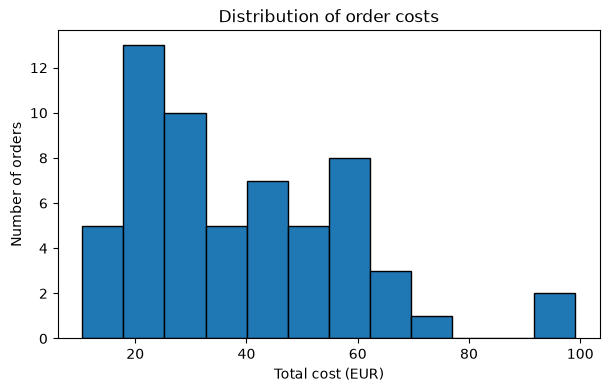

In [8]:
plt.figure(figsize=(7, 4))
plt.hist(df_clean["total_cost_eur"], bins=12, edgecolor="black")
plt.xlabel("Total cost (EUR)")
plt.ylabel("Number of orders")
plt.title("Distribution of order costs")
plt.show()

The histogram shows that the cost of an order varies a lot. Most orders are small: more than half cost less than 40 EUR, and the largest group is between 20 and 30 EUR. There is a second, smaller group of orders around 50-70 EUR, and only a few orders cost more than 70 EUR. The average cost is about 39 EUR, but the median is lower (about 36 EUR), because a few expensive orders pull the average up. This wide spread is a reason why a single flat price for every order would not work, and why it is useful to model the cost from the order's characteristics.

### Correlations

To see which variables are related, we use the Pearson correlation coefficient between two variables $x$ and $y$:

$$r = \frac{\sum_i (x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum_i (x_i-\bar x)^2 \,\sum_i (y_i-\bar y)^2}}.$$

It is always between $-1$ and $1$. Values close to $1$ mean that the variables grow together, values close to $-1$ 
mean that one grows when the other falls, and values close to $0$ mean no linear relationship.

In [9]:
cols = ["quantity", "area_cm2", "ink_ml", "paper_sheets",
        "press_time_min", "design_time_min", "waste_pct", "total_cost_eur"]
corr = df_clean[cols].corr().round(2)
corr

,quantity,area_cm2,ink_ml,paper_sheets,press_time_min,design_time_min,waste_pct,total_cost_eur
quantity,1.00,0.11,0.95,0.97,0.99,-0.06,-0.04,0.59
area_cm2,0.11,1.00,0.24,0.27,0.10,0.16,-0.14,0.12
ink_ml,0.95,0.24,1.00,0.98,0.95,-0.04,-0.06,0.57
paper_sheets,0.97,0.27,0.98,1.00,0.95,-0.02,-0.06,0.59
press_time_min,0.99,0.10,0.95,0.95,1.00,-0.03,-0.06,0.61
design_time_min,-0.06,0.16,-0.04,-0.02,-0.03,1.00,-0.10,0.32
waste_pct,-0.04,-0.14,-0.06,-0.06,-0.06,-0.10,1.00,-0.16
total_cost_eur,0.59,0.12,0.57,0.59,0.61,0.32,-0.16,1.00


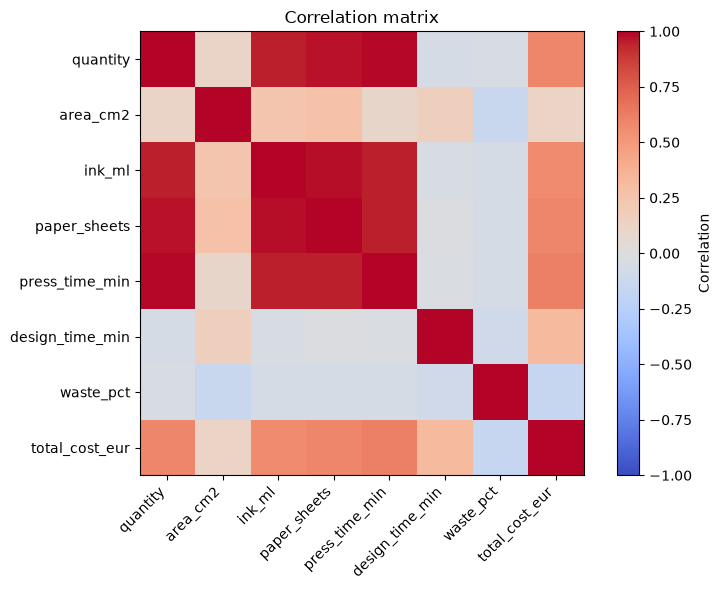

In [10]:
plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(cols)), cols, rotation=45, ha="right")
plt.yticks(range(len(cols)), cols)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

### Multicollinearity

The correlation matrix shows strong relationships between some explanatory
variables. For example, quantity is strongly correlated with ink consumption,
paper consumption and heat-press time.

This situation is known as **multicollinearity**.

Multicollinearity occurs when two or more explanatory variables contain similar
information. In a regression model, this can make the estimated coefficients
unstable.

The correlation coefficient between two variables $X$ and $Y$ is:

$$
r_{XY}
=
\frac{
\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})
}{
\sqrt{
\sum_{i=1}^{n}(x_i-\bar{x})^2
\sum_{i=1}^{n}(y_i-\bar{y})^2
}
}
$$

The value of $r$ is between $-1$ and $1$:

$$
-1 \leq r \leq 1
$$

Values close to $1$ indicate a strong positive linear relationship, while
values close to $-1$ indicate a strong negative relationship.

In this project, strong correlations between production variables are
expected because larger orders generally require more materials and more
production time.

Because of this multicollinearity, Ridge regression will later be compared
with Ordinary Least Squares (OLS).

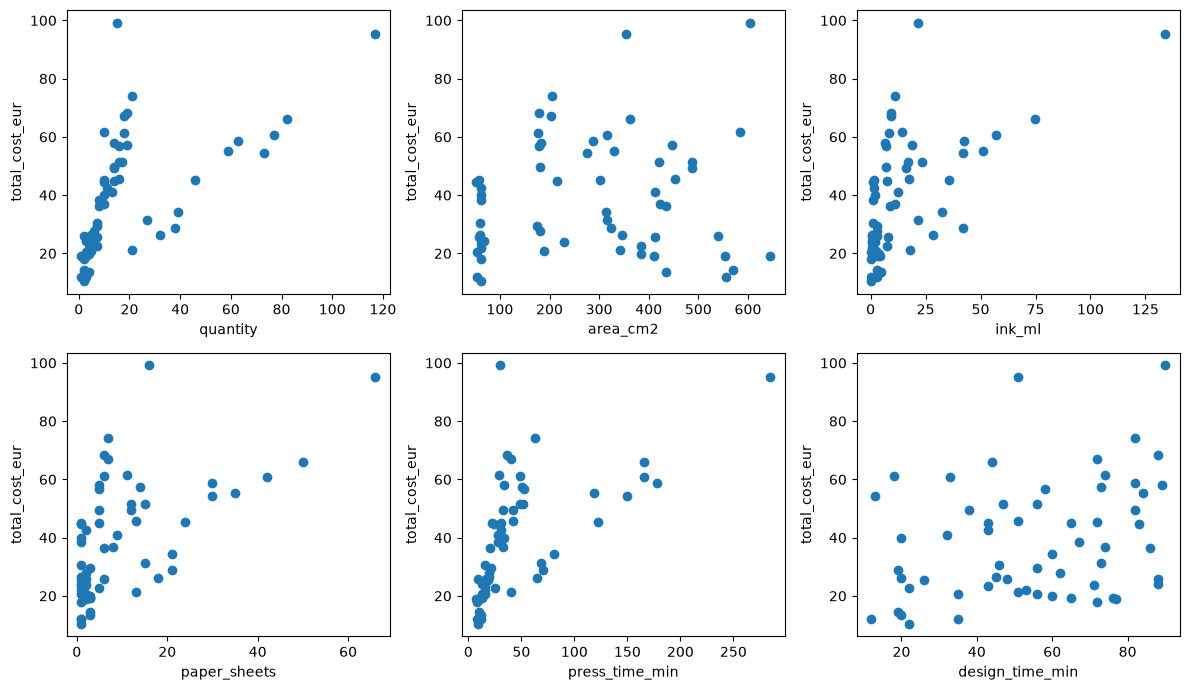

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.flat, cols[:-1][:6]):
    ax.scatter(df_clean[col], df_clean["total_cost_eur"])
    ax.set_xlabel(col)
    ax.set_ylabel("total_cost_eur")
plt.tight_layout()
plt.show()

The correlation matrix shows that `quantity`, `ink_ml`, `paper_sheets` and `press_time_min` are almost perfectly correlated with each other (0.95-0.99). This is expected: a bigger order needs more ink, more paper and more time in the press. Such strongly related predictors can make the coefficients of ordinary least squares unstable, which is why we also try Ridge regression later.

The correlation of each of these variables with the total cost is only about 0.6, because the orders are made of different products with different prices of blanks. Design time has a weaker relationship with cost (0.32), the printed area has almost none (0.12), and the waste percentage is very weakly and negatively correlated (-0.16), which is most likely just random variation in a small sample.

## 6. Modeling

### 6.1 Simple linear regression

We start with the simplest model: the cost depends only on the quantity,

$$y = \beta_0 + \beta_1 x + \varepsilon.$$

For one predictor, the least squares solution has a simple form:

$$\hat\beta_1 = \frac{\sum_i (x_i-\bar x)(y_i-\bar y)}{\sum_i (x_i-\bar x)^2}, \qquad \hat\beta_0 = \bar y - \hat\beta_1 \bar x.$$

The slope $\hat\beta_1$ tells how many euros the cost grows with one more item in the order.

In [12]:
x = df_clean["quantity"].to_numpy()
y = df_clean["total_cost_eur"].to_numpy()

b1 = ((x - x.mean()) * (y - y.mean())).sum() / ((x - x.mean()) ** 2).sum()
b0 = y.mean() - b1 * x.mean()
y_hat = b0 + b1 * x
r2 = 1 - ((y - y_hat) ** 2).sum() / ((y - y.mean()) ** 2).sum()

print(f"Intercept b0 = {b0:.2f} EUR")
print(f"Slope b1 = {b1:.2f} EUR per item")
print(f"R^2 = {r2:.2f}")

Intercept b0 = 29.55 EUR
Slope b1 = 0.51 EUR per item
R^2 = 0.35


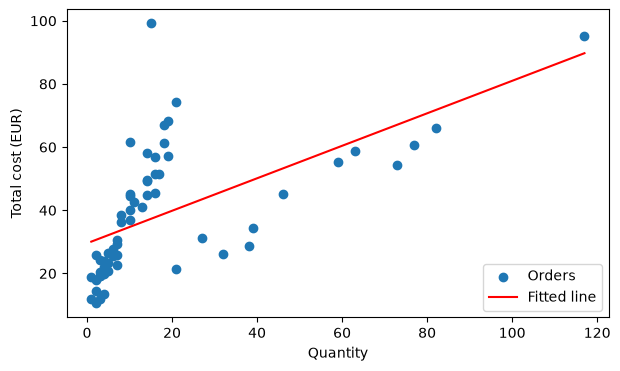

In [13]:
plt.figure(figsize=(7, 4))
plt.scatter(x, y, label="Orders")
xs = np.linspace(x.min(), x.max(), 100)
plt.plot(xs, b0 + b1 * xs, color="red", label="Fitted line")
plt.xlabel("Quantity")
plt.ylabel("Total cost (EUR)")
plt.legend()
plt.show()

The fitted line is $\hat y = 29.55 + 0.51\,x$. The intercept means a "base" cost of about 29.55 EUR for an order, and each additional item adds about 0.51 EUR on average. The coefficient of determination is $R^2 = 0.35$, so the quantity alone explains only 35% of the variation in the cost. This agrees with the correlation $r = 0.59$, because for a simple regression $R^2 = r^2$.

The plot shows why the fit is weak: the line goes between the two groups of orders (expensive items in small amounts and cheap items in large amounts) and describes neither of them well. This motivates a model with more predictors.

### 6.2 Linear regression with matrices

Now we compute the coefficients directly from the formula derived in Section 3,

$$\hat\beta = (X^T X)^{-1} X^T y,$$

using only matrix operations of `numpy`: transposition `.T`, matrix product `@` and inverse `np.linalg.inv`. First we check that for one predictor we get the same numbers as before.

In [14]:
X1 = np.column_stack([np.ones(len(x)), x])   # column of ones and quantity
beta1 = np.linalg.inv(X1.T @ X1) @ X1.T @ y
print(beta1)

[29.55317851  0.51436523]


The matrix formula gives the same intercept and slope as the formulas for simple regression, so the two approaches agree.

In [15]:
features = [
    "product_type",
    "quantity",
    "ink_ml",
    "paper_sheets",
    "press_time_min",
    "design_time_min",
    "waste_pct"
]

X_df = df_clean[features].copy()

X_df = pd.get_dummies(
    X_df,
    columns=["product_type"],
    drop_first=True,
    dtype=float
)

X = np.column_stack([
    np.ones(len(X_df)),
    X_df.to_numpy()
])

y = df_clean["total_cost_eur"].to_numpy()

beta = np.linalg.inv(X.T @ X) @ X.T @ y

feature_names = ["intercept"] + list(X_df.columns)

for name, b in zip(feature_names, beta):
    print(f"{name:25s} {b:8.3f}")

intercept                  -23.062
quantity                     0.961
ink_ml                      -0.529
paper_sheets                 1.297
press_time_min              -0.045
design_time_min              0.232
waste_pct                   -0.513
product_type_mousepad       34.584
product_type_mug            46.759
product_type_phone_case     36.893
product_type_t-shirt        41.261


### 6.3 Interpretation of the OLS coefficients

The estimated coefficients show how the explanatory variables are associated with the predicted production cost while the other variables are held constant.

The model includes `product_type` using one-hot encoding. The omitted product category acts as the reference category, while the coefficients of the remaining product types represent their estimated difference relative to this reference.

For example, `quantity`, `ink_ml`, `paper_sheets`, and `press_time_min` are strongly correlated because larger orders generally require more materials and production time. As a result, ordinary least squares regression can produce unstable coefficients and unexpected signs when the variables contain overlapping information.

Several numerical variables have negative coefficients, such as `ink_ml`, `press_time_min` and `waste_pct`. These negative signs do not mean that more ink, press time or waste reduces the production cost. For `ink_ml` and `press_time_min` they are a consequence of the strong multicollinearity between the explanatory variables. The small negative coefficient of `waste_pct`, however, cannot be explained by multicollinearity, because this variable is almost uncorrelated with the others (Section 5); it is most likely random variation caused by the small sample of 59 orders. Both effects disappear in the interaction model of Section 6.5, where all slope coefficients are positive.

This is an important limitation of the OLS model and provides a motivation for comparing it with Ridge Regression later in the project.

Mathematically, the OLS model estimates the coefficient vector by minimizing the sum of squared residuals:

$$
\hat{\beta}
=
\arg\min_{\beta}
\sum_{i=1}^{n}
(y_i-\hat{y}_i)^2
$$

or, in matrix form:

$$
\hat{\beta}
=
(X^TX)^{-1}X^Ty
$$

The Ridge model will later add a regularization term to reduce the instability of the estimated coefficients.


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 47
Test samples: 12


In [17]:
from sklearn.linear_model import LinearRegression

ols_model = LinearRegression()

ols_model.fit(X_train, y_train)

y_pred = ols_model.predict(X_test)

print("OLS model trained successfully.")

OLS model trained successfully.


In [18]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R²:   {r2:.3f}")
print(f"MAE:  {mae:.3f} EUR")
print(f"RMSE: {rmse:.3f} EUR")

R²:   0.558
MAE:  11.240 EUR
RMSE: 12.102 EUR


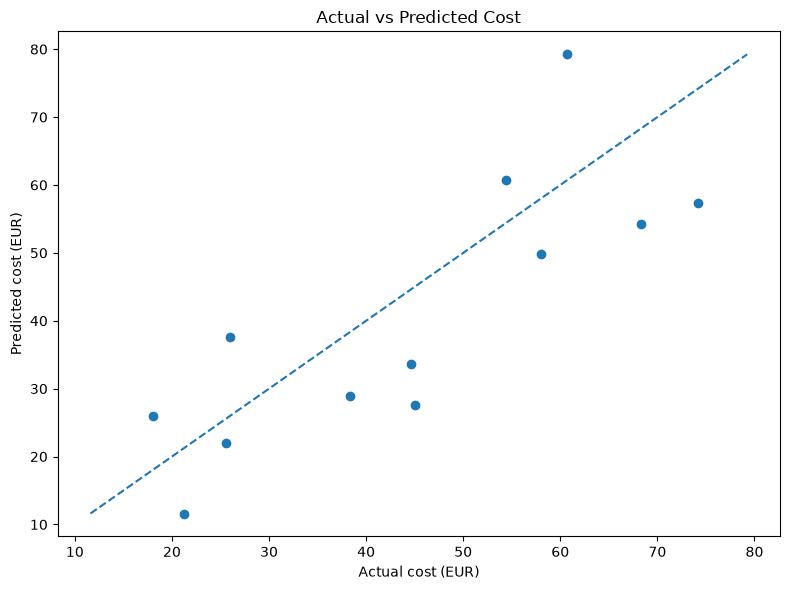

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual cost (EUR)")
plt.ylabel("Predicted cost (EUR)")
plt.title("Actual vs Predicted Cost")

plt.tight_layout()
plt.show()

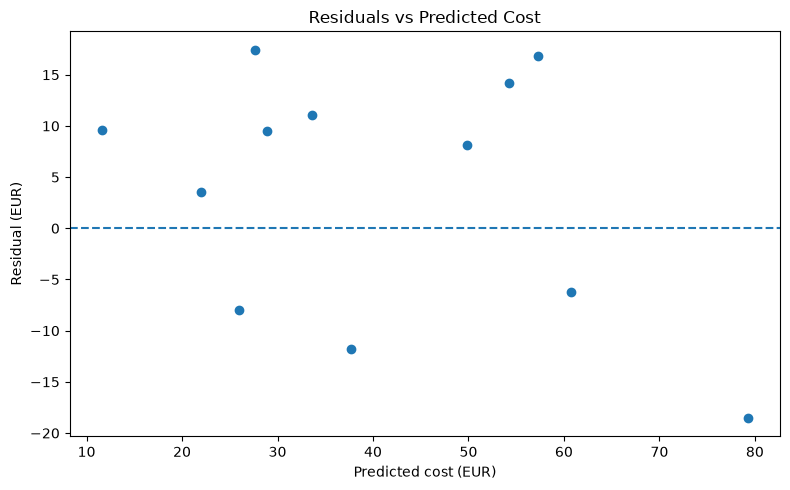

In [20]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted cost (EUR)")
plt.ylabel("Residual (EUR)")
plt.title("Residuals vs Predicted Cost")

plt.tight_layout()
plt.show()

In [21]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    ols_model,
    X,
    y,
    cv=5,
    scoring="r2"
)

print("Cross-validation R² scores:")
print(np.round(cv_scores, 3))

print("Mean CV R²:", round(cv_scores.mean(), 3))

Cross-validation R² scores:
[ 0.486  0.284 -0.339  0.469 -0.034]
Mean CV R²: 0.173


In [22]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=1.0))
])

ridge_model.fit(X_train, y_train)

ridge_pred = ridge_model.predict(X_test)

print("Ridge model trained successfully.")

Ridge model trained successfully.


In [23]:
ridge_r2 = r2_score(y_test, ridge_pred)
ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred))

print(f"Ridge R²:   {ridge_r2:.3f}")
print(f"Ridge MAE:  {ridge_mae:.3f} EUR")
print(f"Ridge RMSE: {ridge_rmse:.3f} EUR")


Ridge R²:   0.616
Ridge MAE:  9.920 EUR
Ridge RMSE: 11.279 EUR


In [24]:
ridge_cv_scores = cross_val_score(
    ridge_model,
    X,
    y,
    cv=5,
    scoring="r2"
)

print("Ridge cross-validation R² scores:")
print(np.round(ridge_cv_scores, 3))

print("Mean Ridge CV R²:", round(ridge_cv_scores.mean(), 3))

Ridge cross-validation R² scores:
[0.501 0.234 0.64  0.42  0.125]
Mean Ridge CV R²: 0.384


In [25]:
comparison = pd.DataFrame({
    "Model": ["OLS", "Ridge"],
    "R²": [r2, ridge_r2],
    "MAE (EUR)": [mae, ridge_mae],
    "RMSE (EUR)": [rmse, ridge_rmse],
    "Mean CV R²": [cv_scores.mean(), ridge_cv_scores.mean()]
})

comparison

,Model,R²,MAE (EUR),RMSE (EUR),Mean CV R²
0,OLS,0.557819,11.239569,12.101578,0.173134
1,Ridge,0.615900,9.920405,11.278831,0.383769


### 6.4 OLS vs Ridge Regression

The results show that Ridge Regression performs better than Ordinary Least Squares (OLS) on the synthetic dataset.

The OLS model achieved a test $R^2$ of 0.558, while the Ridge model achieved a higher $R^2$ of 0.616. At the same time, Ridge reduced the Mean Absolute Error (MAE) from 11.240 EUR to 9.920 EUR and the Root Mean Squared Error (RMSE) from 12.102 EUR to 11.279 EUR.

The cross-validation results also indicate better stability for Ridge Regression. The mean cross-validation $R^2$ increased from 0.173 for OLS to 0.384 for Ridge.

This improvement is consistent with the strong multicollinearity present in the dataset. Several predictors, such as quantity, ink consumption, paper usage, and press time, are strongly correlated. OLS can produce unstable coefficient estimates in the presence of multicollinearity.

Ridge Regression addresses this problem by adding an $L_2$ regularization term to the ordinary least squares objective function:

$$
\hat{\beta}_{Ridge}
=
\arg\min_{\beta}
\left[
\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
+
\alpha\sum_{j=1}^{p}\beta_j^2
\right]
$$

where $\alpha$ controls the strength of regularization.

The regularization term penalizes large coefficients and reduces their magnitude. This can make the model more stable when predictors are strongly correlated.

For this dataset, Ridge Regression provides better predictive performance and better cross-validation stability than OLS. However, the dataset contains only 59 observations, so these results should be interpreted as evidence for this particular dataset rather than as a general conclusion that Ridge is always superior to OLS.


### 6.5 Interaction model: quantity × product type

The scatter plots in Section 5 showed two groups of orders with different slopes. The reason is that the cost of one more item depends on the product: an invitation is much cheaper than a t-shirt. A model with a single coefficient for `quantity` cannot describe this.

We add an **interaction** between the quantity $q$ and the product indicators $d_k$ (equal to 1 if the order is of product $k$ and 0 otherwise):

$$ y = \beta_0 + \beta_1 q + \sum_k \gamma_k d_k + \sum_k \delta_k \,(q \cdot d_k) + \dots + \varepsilon.$$

For the reference product (invitation) one more item costs $\beta_1$, and for product $k$ it costs $\beta_1 + \delta_k$. The model is still linear in the coefficients, so the matrix formula $\hat\beta = (X^T X)^{-1} X^T y$ works without any change; we only add new columns to $X$.

In [26]:
product_cols = [c for c in X_df.columns if c.startswith("product_type_")]

X_int_df = X_df.copy()
for col in product_cols:
    X_int_df[f"quantity_x_{col}"] = X_df["quantity"] * X_df[col]

X_int = np.column_stack([np.ones(len(X_int_df)), X_int_df.to_numpy()])
print("Number of columns in X (with intercept):", X_int.shape[1])

beta_int = np.linalg.inv(X_int.T @ X_int) @ X_int.T @ y

names_int = ["intercept"] + list(X_int_df.columns)
for name, b in zip(names_int, beta_int):
    print(f"{name:35s} {b:8.3f}")

Number of columns in X (with intercept): 15
intercept                             -2.184
quantity                               0.598
ink_ml                                 0.011
paper_sheets                           0.046
press_time_min                         0.052
design_time_min                        0.145
waste_pct                              0.200
product_type_mousepad                  2.603
product_type_mug                       1.944
product_type_phone_case                1.854
product_type_t-shirt                   2.037
quantity_x_product_type_mousepad       1.721
quantity_x_product_type_mug            2.251
quantity_x_product_type_phone_case     2.649
quantity_x_product_type_t-shirt        4.735


In [27]:
base_slope = beta_int[names_int.index("quantity")]
slopes = {"invitation": base_slope}
for col in product_cols:
    slopes[col.replace("product_type_", "")] = (
        base_slope + beta_int[names_int.index(f"quantity_x_{col}")]
    )

print("Estimated cost of one more item (EUR), by product:")
for product, s in sorted(slopes.items(), key=lambda kv: kv[1]):
    print(f"  {product:12s} {s:6.2f}")

Estimated cost of one more item (EUR), by product:
  invitation     0.60
  mousepad       2.32
  mug            2.85
  phone_case     3.25
  t-shirt        5.33


In [28]:
Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    X_int, y, test_size=0.20, random_state=42
)

ols_int = LinearRegression().fit(Xi_train, yi_train)
ridge_int = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=1.0))
]).fit(Xi_train, yi_train)

rows = []
for name, model in [("OLS + interactions", ols_int),
                    ("Ridge + interactions", ridge_int)]:
    pred = model.predict(Xi_test)
    cv_int = cross_val_score(model, X_int, y, cv=5, scoring="r2")
    rows.append({
        "Model": name,
        "R²": r2_score(yi_test, pred),
        "MAE (EUR)": mean_absolute_error(yi_test, pred),
        "RMSE (EUR)": np.sqrt(mean_squared_error(yi_test, pred)),
        "Mean CV R²": cv_int.mean(),
    })

comparison_int = pd.DataFrame(rows)
comparison_int.round(3)

,Model,R²,MAE (EUR),RMSE (EUR),Mean CV R²
0,OLS + interactions,0.991,1.429,1.770,0.985
1,Ridge + interactions,0.982,1.682,2.447,0.982


Adding the interaction between quantity and product type improves the model dramatically. On the test set, OLS reaches $R^2 = 0.991$ with a mean absolute error of 1.43 EUR, compared with $R^2 = 0.558$ and 11.24 EUR for the model without interactions. The mean cross-validated $R^2$ increases from 0.173 to 0.985.

The coefficients are now also sensible: one more item costs about 0.60 EUR for an invitation and 5.33 EUR for a t-shirt, which follows the price of the blank items. The strange negative signs from the earlier model disappeared.

Once the model has the right structure, Ridge no longer helps: OLS (0.991) is slightly better than Ridge (0.982). This suggests that the main source of error before was the missing product-specific slope and not the multicollinearity itself.

*Caution:* the data are simulated from a formula in which the cost per item depends on the product, so such a nearly perfect fit should not be expected with real orders.

## 7. Model Diagnostics

Model diagnostics are used to evaluate whether the regression model is appropriate for the data and whether its predictions and errors show systematic patterns.

In this section, the residuals of the baseline OLS model will be examined using graphical and statistical methods. Residuals represent the difference between the observed cost and the cost predicted by the model:

$$
e_i = y_i - \hat{y}_i
$$

where $e_i$ is the residual, $y_i$ is the observed cost, and $\hat{y}_i$ is the predicted cost.

The main diagnostic checks will focus on the distribution of residuals, their relationship with predicted values, and the presence of systematic patterns. These checks help determine whether the model errors are reasonably well behaved and whether there are indications of model misspecification.

Because the dataset is relatively small and synthetic, the diagnostic results will be interpreted as evidence about the behavior of the model on this particular dataset rather than as universal conclusions.


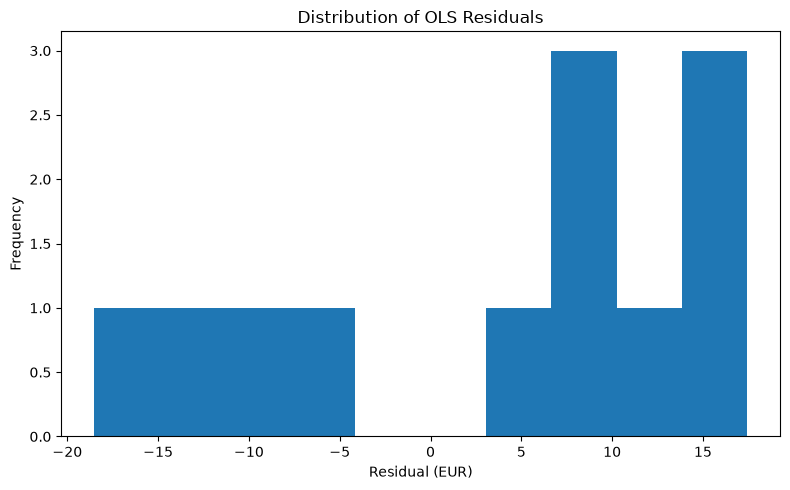

In [29]:
plt.figure(figsize=(8, 5))

plt.hist(residuals, bins=10)

plt.xlabel("Residual (EUR)")
plt.ylabel("Frequency")
plt.title("Distribution of OLS Residuals")

plt.tight_layout()
plt.show()

In [30]:
print("Mean residual:", round(residuals.mean(), 3))
print("Median residual:", round(np.median(residuals), 3))
print("Standard deviation:", round(residuals.std(), 3))
print("Minimum residual:", round(residuals.min(), 3))
print("Maximum residual:", round(residuals.max(), 3))

Mean residual: 3.826
Median residual: 8.85
Standard deviation: 11.481
Minimum residual: -18.537
Maximum residual: 17.442


### Interpretation of the Residual Distribution

The residuals range from approximately **-18.54** EUR to **17.44** EUR, with a standard deviation of **11.48** EUR. This indicates that the prediction errors have a noticeable spread around the expected value.

The mean residual is **3.83** EUR, while the median residual is **8.85** EUR. Both values are positive, indicating a tendency of the OLS model to underestimate the actual cost for a substantial part of the test observations.

The difference between the mean and median residual also suggests that the residual distribution is not perfectly symmetric. Therefore, the residuals should not be considered perfectly normally distributed based on these descriptive statistics alone.

Since the dataset contains only 59 observations, small deviations from normality are not unexpected. The residual distribution will therefore be considered together with the other diagnostic checks rather than used as a standalone criterion for rejecting the model.


### Residuals vs Predicted Values

A residuals-versus-predicted plot is used to examine whether the model errors show systematic patterns.

The residuals are calculated as:

$$
e_i = y_i - \hat{y}_i
$$

where $y_i$ is the observed cost and $\hat{y}_i$ is the predicted cost.

In a well-behaved linear regression model, the residuals should be distributed approximately randomly around the horizontal zero line. There should be no clear curve, trend, or funnel-shaped pattern.

A systematic pattern may indicate that the model does not fully capture the relationship between the predictors and the target variable. Increasing spread of residuals as the predicted value increases may also indicate heteroscedasticity.

The following plot is used to visually assess these patterns.


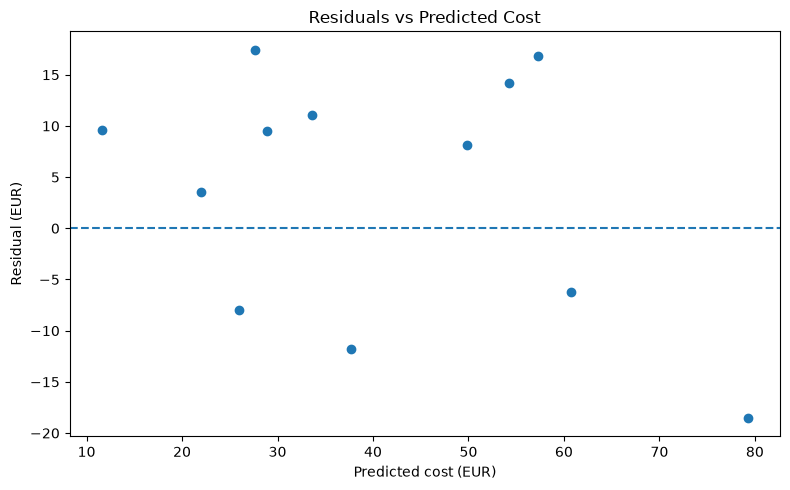

In [31]:
plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted cost (EUR)")
plt.ylabel("Residual (EUR)")
plt.title("Residuals vs Predicted Cost")

plt.tight_layout()
plt.show()

In [32]:
correlation = np.corrcoef(y_pred, residuals)[0, 1]

print("Correlation between predicted values and residuals:",
      round(correlation, 3))

Correlation between predicted values and residuals: -0.352


### Interpretation of Residuals vs Predicted Values

The correlation between the predicted values and the residuals is **-0.352**. This indicates a moderate negative relationship between predicted cost and prediction errors.

The result suggests that the residuals are not completely independent of the predicted values and that the OLS model may contain some systematic prediction error. However, the correlation is not strong enough to indicate a severe problem by itself.

Overall, the residual analysis suggests that the model provides useful predictions, but its errors are not perfectly random. This is reasonable given the small size and synthetic nature of the dataset.


In [33]:
from scipy.stats import shapiro

stat, p_value = shapiro(residuals)

print("Shapiro-Wilk statistic:", round(stat, 3))
print("p-value:", round(p_value, 3))

Shapiro-Wilk statistic: 0.9
p-value: 0.161


### Interpretation of the Shapiro-Wilk Test

The Shapiro-Wilk test was used to assess whether the residuals are approximately normally distributed.

The test produced a statistic of **0.900** and a p-value of **0.161**. Since the p-value is greater than 0.05, there is insufficient evidence to reject the assumption of normality.

Therefore, the residuals can be considered approximately normally distributed for this dataset. However, the result should be interpreted cautiously because the test set contains only 12 observations.

Overall, the diagnostic checks indicate that the OLS model has some systematic prediction error, but there is no strong statistical evidence of a serious violation of the normality assumption.


### Diagnostics of the final model

The diagnostics above concern the baseline OLS model and only 12 test observations. Here we examine the final model (OLS with the quantity × product type interaction) on all 59 orders. To obtain honest residuals, every order is predicted by a model that was fitted without it (5-fold cross-validation).

In [34]:
from sklearn.model_selection import KFold, cross_val_predict
from scipy.stats import shapiro, spearmanr

kfold = KFold(n_splits=5, shuffle=True, random_state=42)
y_cv_pred = cross_val_predict(LinearRegression(), X_int, y, cv=kfold)
cv_residuals = y - y_cv_pred

print("Number of residuals:", len(cv_residuals))
print("Mean residual:  ", round(cv_residuals.mean(), 3))
print("Median residual:", round(np.median(cv_residuals), 3))
print("Std of residuals:", round(cv_residuals.std(), 3))
print("Min / max:", round(cv_residuals.min(), 3), "/", round(cv_residuals.max(), 3))
print("Correlation(pred, residual):", round(np.corrcoef(y_cv_pred, cv_residuals)[0, 1], 3))

stat, p = shapiro(cv_residuals)
print("Shapiro-Wilk statistic:", round(stat, 3), " p-value:", round(p, 3))

rho, p_rho = spearmanr(y_cv_pred, np.abs(cv_residuals))
print("Spearman(pred, |residual|):", round(rho, 3), " p-value:", round(p_rho, 3))

Number of residuals: 59
Mean residual:   0.02
Median residual: -0.033
Std of residuals: 2.501
Min / max: -6.992 / 10.946
Correlation(pred, residual): 0.098
Shapiro-Wilk statistic: 0.901  p-value: 0.0
Spearman(pred, |residual|): 0.397  p-value: 0.002


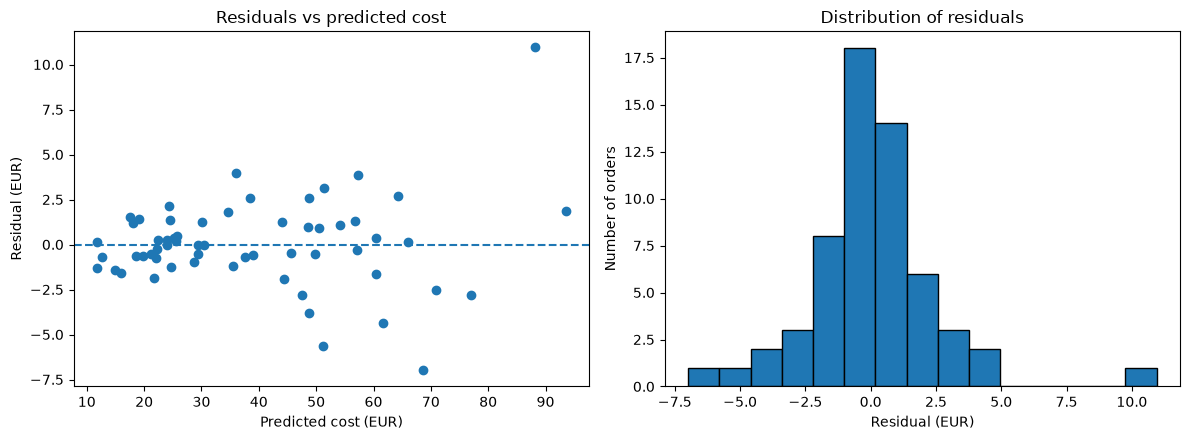

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(y_cv_pred, cv_residuals)
axes[0].axhline(0, linestyle="--")
axes[0].set_xlabel("Predicted cost (EUR)")
axes[0].set_ylabel("Residual (EUR)")
axes[0].set_title("Residuals vs predicted cost")

axes[1].hist(cv_residuals, bins=15, edgecolor="black")
axes[1].set_xlabel("Residual (EUR)")
axes[1].set_ylabel("Number of orders")
axes[1].set_title("Distribution of residuals")

plt.tight_layout()
plt.show()

The residuals of the final model are centered at zero (mean 0.02 EUR) with a standard deviation of 2.50 EUR, and the typical error is about 4% of the cost (mean absolute error 1.68 EUR) . The correlation between the predicted values and the residuals is only 0.098, so there is no linear pattern left, which supports the linearity assumption.

Two assumptions, however, are not fully satisfied. The Shapiro-Wilk test gives $p < 0.001$, so the residuals are not normally distributed. The histogram shows heavy tails, mostly caused by one order of t-shirts, which was underestimated by about 11 EUR. In addition, the Spearman correlation between the predicted cost and the absolute residuals is 0.40 ($p = 0.002$), which means that the errors grow together with the cost, i.e. the variance is not constant (heteroscedasticity). This is natural, because the errors are roughly proportional to the cost.

These violations have little effect on the point predictions used by the price calculator, but confidence intervals and significance tests based on constant variance and normal errors would not be reliable. A possible improvement is to model the logarithm of the cost or to use weighted least squares.

## 8. Comparison of Methods

### 8.1 OLS vs Ridge Regression

This section compares the performance of Ordinary Least Squares (OLS) and Ridge Regression using the same training and test data.

The models are evaluated using three standard regression metrics:

$$
R^2 = 1 - \frac{\sum (y_i-\hat{y}_i)^2}{\sum (y_i-\bar{y})^2}
$$

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|
$$

$$
RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}
$$

A higher $R^2$ indicates a better fit, while lower MAE and RMSE indicate smaller prediction errors.

The comparison is particularly relevant because the dataset contains strong multicollinearity between several predictors. Ridge Regression is designed to reduce the effect of multicollinearity through regularization.


In [42]:
comparison

,Model,R²,MAE (EUR),RMSE (EUR),Mean CV R²
0,OLS,0.557819,11.239569,12.101578,0.173134
1,Ridge,0.615900,9.920405,11.278831,0.383769


In [36]:
comparison_all = pd.concat([comparison, comparison_int], ignore_index=True)
comparison_all.round(3)

,Model,R²,MAE (EUR),RMSE (EUR),Mean CV R²
0,OLS,0.558,11.240,12.102,0.173
1,Ridge,0.616,9.920,11.279,0.384
2,OLS + interactions,0.991,1.429,1.770,0.985
3,Ridge + interactions,0.982,1.682,2.447,0.982


### 8.2 Interpretation of the Results

Without interactions, Ridge Regression performs better than OLS: it has a higher test $R^2$ (**0.616** compared with **0.558**), lower MAE (**9.92 EUR** compared with **11.24 EUR**) and a higher mean cross-validated $R^2$ (**0.384** compared with **0.173**). This agrees with the strong multicollinearity between quantity, ink, paper and press time, which Ridge handles better.

However, the largest improvement comes from the structure of the model and not from the regularization. After adding the interaction between quantity and product type (Section 6.5), the test $R^2$ increases to **0.991** for OLS and **0.982** for Ridge, the MAE falls to about 1.4-1.7 EUR, and the mean cross-validated $R^2$ reaches about **0.98**.

With the interaction, OLS is slightly better than Ridge, so the regularization is no longer needed. Therefore the final model is **OLS with the quantity × product type interaction**, and it is the model used in the price calculator.

These results are based on a small simulated dataset and a test set of only 12 orders, so they should be interpreted with caution.

## 9. Price Calculator

### 9.1 Recommended Price Calculation

The regression model can be used to estimate the production cost of a new sublimation order. Based on this estimated cost, a recommended selling price can be calculated by adding a desired profit margin.

The recommended price is calculated as:

$$
Price = \frac{Predicted\ Cost}{1 - Margin}
$$

where $Margin$ is expressed as a decimal. For example, a target profit margin of 30% is represented as **0.30**.

The calculator will accept the order parameters used by the regression model and return the predicted production cost and the recommended selling price.


In [37]:
# After validating on the test set, refit the final model on all orders
final_model = LinearRegression().fit(X_int, y)

In [38]:
def recommend_price(order, model, margin=0.3):
    """Return the recommended selling price for an order."""

    if not 0 <= margin < 1:
        raise ValueError("Margin must be between 0 and 1.")

    product_types = ["mousepad", "mug", "phone_case", "t-shirt"]

    if order["product_type"] not in product_types + ["invitation"]:
        raise ValueError("Unknown product type.")

    product_flags = [
        1.0 if order["product_type"] == product else 0.0
        for product in product_types
    ]
    quantity = order["quantity"]

    features = [
        1.0,
        quantity,
        order["ink_ml"],
        order["paper_sheets"],
        order["press_time_min"],
        order["design_time_min"],
        order["waste_pct"],
    ]
    features += product_flags
    features += [quantity * flag for flag in product_flags]

    predicted_cost = model.predict([features])[0]
    return predicted_cost / (1 - margin)

In [39]:
example_order = {
    "product_type": "mug",
    "quantity": 10,
    "area_cm2": 785,
    "ink_ml": 12,
    "paper_sheets": 2,
    "press_time_min": 15,
    "design_time_min": 20,
    "waste_pct": 5
}

price = recommend_price(
    example_order,
    final_model,
    margin=0.30
)

print("Recommended price:", round(price, 2), "EUR")

Recommended price: 47.38 EUR


### 9.2 Example Calculation

For the example order of 10 mugs, the calculator uses the final model: OLS with the interaction between quantity and product type, refitted on all 59 orders after it was validated on the test set. The estimated production cost is approximately **33.16 EUR**. With a target profit margin of 30%, the recommended selling price is

$$
P = \frac{33.16}{1 - 0.30} \approx 47.38\text{ EUR}.
$$

Because the dataset is simulated, we can check this estimate against the true cost formula used to generate the data. For the same order it gives 26.25 EUR for the blanks, 1.80 EUR for ink, 0.10 EUR for paper, 1.80 EUR for the press and 3.00 EUR for the design, i.e. **32.95 EUR** in total. The model's estimate is therefore off by less than 1%, while the earlier Ridge model without interactions estimated 31.11 EUR (an error of about 6%).

With real data, such a close agreement should not be expected. The result is an estimate rather than a guaranteed market price, and it should be validated against real production costs before practical use.

### 9.3 A simplified calculator using only information known in advance

The model above uses the amount of ink, the number of paper sheets and the press time. These values are not known when a customer asks for a quote. We therefore build a simplified model with only the quantity $x_1$, the design time $x_5$, the product type $d_k$ and the interaction between quantity and product (notation of Section 2):

$$
y = \beta_0 + \beta_1 x_1 + \beta_5 x_5 + \sum_{k=1}^{4}\gamma_k d_k + \sum_{k=1}^{4}\delta_k\,(x_1 d_k) + \varepsilon
$$

The waste percentage is also left out, because it is not known before production either. From the mathematical point of view, this simplification is reasonable: ink, paper and press time are almost proportional to the quantity (correlations 0.95-0.99, Section 5), so once the quantity and the product are in the model, they carry very little additional information. The simplified model has fewer coefficients, so it is also easier to interpret and less prone to overfitting.

In [40]:
simple_cols = ["quantity", "design_time_min"] + [
    c for c in X_int_df.columns
    if c.startswith("product_type_") or c.startswith("quantity_x_")
]
X_simple = X_int_df[simple_cols].to_numpy()

Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_simple, y, test_size=0.20, random_state=42
)
simple_model = LinearRegression().fit(Xs_train, ys_train)
simple_pred = simple_model.predict(Xs_test)
full_pred = ols_int.predict(Xi_test)

comparison_simple = pd.DataFrame({
    "Model": ["Full interaction model", "Simplified model"],
    "Number of predictors": [X_int.shape[1] - 1, X_simple.shape[1]],
    "R²": [r2_score(yi_test, full_pred), r2_score(ys_test, simple_pred)],
    "MAE (EUR)": [mean_absolute_error(yi_test, full_pred),
                  mean_absolute_error(ys_test, simple_pred)],
    "Mean CV R²": [
        cross_val_score(LinearRegression(), X_int, y, cv=5, scoring="r2").mean(),
        cross_val_score(LinearRegression(), X_simple, y, cv=5, scoring="r2").mean(),
    ],
})
comparison_simple.round(3)

,Model,Number of predictors,R²,MAE (EUR),Mean CV R²
0,Full interaction model,14,0.991,1.429,0.985
1,Simplified model,10,0.991,1.339,0.987


In [41]:
simple_final_model = LinearRegression().fit(X_simple, y)


def recommend_price_simple(order, model, margin=0.3):
    """Return the estimated cost and the recommended price of an order,
    using only information that is known before production starts."""

    if not 0 <= margin < 1:
        raise ValueError("Margin must be between 0 and 1.")

    product_types = ["mousepad", "mug", "phone_case", "t-shirt"]

    if order["product_type"] not in product_types + ["invitation"]:
        raise ValueError("Unknown product type.")

    product_flags = [
        1.0 if order["product_type"] == product else 0.0
        for product in product_types
    ]
    quantity = order["quantity"]

    features = [quantity, order["design_time_min"]]
    features += product_flags
    features += [quantity * flag for flag in product_flags]

    predicted_cost = model.predict([features])[0]
    return predicted_cost, predicted_cost / (1 - margin)


simple_order = {"product_type": "mug", "quantity": 10, "design_time_min": 20}
cost, price = recommend_price_simple(simple_order, simple_final_model, margin=0.30)
print("Estimated cost:", round(cost, 2), "EUR")
print("Recommended price:", round(price, 2), "EUR")

Estimated cost: 33.66 EUR
Recommended price: 48.08 EUR


For the same example order of 10 mugs, the simplified calculator needs only three inputs (product, quantity and design time) and estimates the cost at about **33.66 EUR** and the recommended price at **48.08 EUR**. The full model gave 33.16 EUR and 47.38 EUR, and the true cost from the generating formula is 32.95 EUR, so the simplified estimate is about 2% above the true cost.

The comparison above shows that the simplified model is as accurate as the full one on the test set ($R^2 = 0.991$ for both) and in cross-validation (0.987 against 0.985), although it uses 10 instead of 14 predictors. Therefore, the simplified model is the one that can be used in practice for quoting a price in advance, while the full model remains useful when the real consumption of ink, paper and press time is known after the production.

## 10. Conclusions & Next Steps

### 10.1 Conclusions

This project developed a regression-based pricing model for sublimation printing orders using mathematical modeling and Python.

The analysis explored the relationship between the production cost and several order characteristics: quantity, ink usage, paper consumption, press time, design time, waste percentage and product type.

First, two baseline models were compared. Ordinary Least Squares (OLS) reached a test $R^2$ of **0.558** (MAE **11.24 EUR**), and Ridge Regression reached **0.616** (MAE **9.92 EUR**). Ridge was also more stable in cross-validation (mean $R^2$ of **0.384** compared with **0.173**), because it handles the strong multicollinearity between quantity, ink, paper and press time better. However, the errors of both models remained large.

The scatter plots suggested that the cost of one more item depends on the product. After adding an interaction between quantity and product type, the test $R^2$ of OLS increased to **0.991**, the MAE fell to **1.43 EUR** and the mean cross-validated $R^2$ reached **0.985**. The estimated cost of one more item ranges from about 0.60 EUR for an invitation to 5.33 EUR for a t-shirt. With the interaction, Ridge (**0.982**) no longer outperformed OLS, so the final model is OLS with the quantity × product type interaction. The main lesson is that an appropriate model structure mattered more than regularization.

Finally, the model was integrated into a price calculator. For the example order of 10 mugs it estimates a production cost of **33.16 EUR** and, with a target margin of 30%, a selling price of **47.38 EUR**. The true cost formula used to generate the data gives 32.95 EUR for this order, so the estimate is off by less than 1%.

Overall, the project demonstrates how regression analysis, linear algebra, model evaluation and Python programming can be combined to investigate a practical pricing problem.

### 10.2 Limitations

The dataset contains only **59 observations** after data cleaning and was synthetically generated for educational purposes. Therefore, it may not reflect the actual costs and pricing patterns of a real sublimation printing business.

The very high accuracy of the interaction model reflects the simulated data, in which the cost per item depends on the product by construction. Real orders contain additional sources of variation, so a lower accuracy should be expected on real data.

The small dataset limits the model's ability to generalize to new orders. The test results are based on only 12 observations, and cross-validation scores vary across different data splits.

In the baseline models, strong multicollinearity between several predictors made individual regression coefficients difficult to interpret, and some coefficients were negative even though the corresponding production activity normally increases cost.

The data cleaning procedure excludes one observation using a predefined cost-per-unit ratio threshold. This decision may affect the results and should be reconsidered when real data becomes available.

In addition, the price calculator depends on the accuracy of the predicted production cost. Its recommendations should not be treated as guaranteed costs or market-optimal prices without validation against real business data.

The price calculator in Section 9.1 requires the amount of ink, the number of paper sheets and the press time of the order. These values are known only after the order has been produced, so they cannot be used to quote a price in advance. Section 9.3 therefore presents a simplified model that uses only information available before production: the quantity, the product type and the design time.

### 10.3 Possible Improvements

Future development could include:

* collecting real production cost and sales data from completed orders;
* increasing the number and variety of observations;
* incorporating actual material prices, electricity consumption, labor costs and equipment depreciation;
* investigating the effect of product area and other relevant product characteristics;
* improving data cleaning and validating outlier thresholds;
* testing polynomial terms and other interactions (for example between product area and quantity), and tuning the Ridge regularization parameter;
* evaluating the model on a separate dataset containing real orders;
* developing a user-friendly graphical interface for the price calculator;
* comparing predicted prices with actual selling prices and realized profit margins.

These improvements would help determine whether the model can provide reliable support for real-world pricing decisions.

## 11. References

1. Python Software Foundation. *Python Documentation*.  
   https://docs.python.org/3/

2. NumPy Developers. *NumPy Documentation*.  
   https://numpy.org/doc/

3. pandas Development Team. *pandas Documentation*.  
   https://pandas.pydata.org/docs/

4. Matplotlib Development Team. *Matplotlib Documentation*.  
   https://matplotlib.org/stable/

5. SciPy Developers. *SciPy Documentation*.  
   https://docs.scipy.org/doc/scipy/

6. scikit-learn Developers. *scikit-learn Documentation*.  
   https://scikit-learn.org/stable/

7. scikit-learn Developers. *Linear Models — Linear Regression and Ridge Regression*.  
   https://scikit-learn.org/stable/modules/linear_model.html

8. James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning: with Applications in R* (2nd ed.). Springer.  
   https://www.statlearning.com/


### Use of AI assistance

Parts of this project were prepared with the help of an AI assistant (Claude, by Anthropic). The assistant helped with: structuring the notebook, generating the simulated dataset (`generate_data.py`), drafting code and suggesting improvements after reviewing my work. I ran all the code myself, checked the results, and I'm responsible for the final content and conclusions of this project.